# Beat the Grid: the analysis, step by step

**Question:** can one open machine-learning model forecast tomorrow's hourly electricity demand better than the
official day-ahead forecasts published by America's grid operators?

This notebook works only from the three published result tables (described in [DATA.md](../DATA.md)), so anyone can
rerun it in a minute without the 3-hour data download. It walks through:

1. Loading and checking the data
2. The headline comparison, weighted by demand
3. Region by region
4. When the model wins: hour of day and season
5. The days that matter most (peak demand)
6. Are the 80% prediction ranges honest?
7. Combining both forecasts
8. The biggest misses
9. What it adds up to

Everything here is a backtest: each quarter was forecast by a model trained only on earlier data, using only
information available the morning before. The live record is on the [website](https://maxliston.github.io/beat-the-grid/#live).

In [1]:
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

DATA = "../docs/data/sql/"   # or "https://maxliston.github.io/beat-the-grid/data/sql/"
hourly = pd.read_parquet(DATA + "hourly.parquet")
regions = pd.read_parquet(DATA + "regions.parquet")
peaks = pd.read_parquet(DATA + "peaks.parquet")
for t in (hourly, peaks):
    t["local_date"] = pd.to_datetime(t.local_date)   # stored as dates; datetimes are easier to group

BLUE, ORANGE, GRAY = "#2a6fd0", "#e2612a", "#8a8375"   # my model, official forecast, neutral (the website's colors)
PAPER, INK, RULE = "#f4f0e6", "#191612", "#dcd4c3"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "text.color": INK, "axes.grid": True, "grid.color": RULE, "grid.alpha": 1,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10,
                     "axes.titlepad": 10, "legend.frameon": False})
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=[BLUE, ORANGE, GRAY])
SERIF = {"family": ["Georgia", "DejaVu Serif", "serif"]}                  # titles in a serif, like the site's headlines
pd.set_option("display.precision", 3)
print(f"hourly: {len(hourly):,} rows · regions: {len(regions)} · peaks: {len(peaks):,} region-days")

hourly: 696,190 rows · regions: 34 · peaks: 28,746 region-days


## 1. Loading and checking the data

In [2]:
hourly.head()

,region,hour_ending_utc,local_date,local_hour,actual_mw,official_mw,ours_mw,ours_low_mw,ours_high_mw,blend_mw
0,AECI,2024-07-01 06:00:00,2024-07-01,0,2093,1970,2072,1893,2420,2021
1,AECI,2024-07-01 07:00:00,2024-07-01,1,1993,1838,1931,1781,2287,1884
2,AECI,2024-07-01 08:00:00,2024-07-01,2,1902,1755,1864,1723,2245,1810
3,AECI,2024-07-01 09:00:00,2024-07-01,3,1879,1704,1835,1671,2226,1769
4,AECI,2024-07-01 10:00:00,2024-07-01,4,1855,1714,1808,1644,2256,1761


In [3]:
hourly.dtypes

region                        str
hour_ending_utc    datetime64[us]
local_date          datetime64[s]
local_hour                   int8
actual_mw                   int32
official_mw                 int32
ours_mw                     int32
ours_low_mw                 int32
ours_high_mw                int32
blend_mw                    int32
dtype: object

In [4]:
# Missing values, impossible values, and coverage
checks = pd.Series({
    "missing values": int(hourly.isna().sum().sum()),
    "non-positive actual demand": int((hourly.actual_mw <= 0).sum()),
    "range low > high": int((hourly.ours_low_mw > hourly.ours_high_mw).sum()),
    "duplicate region-hours": int(hourly.duplicated(["region", "hour_ending_utc"]).sum()),
    "first day": hourly.local_date.min().date(),
    "last day": hourly.local_date.max().date(),
})
checks

missing values                         0
non-positive actual demand             0
range low > high                       0
duplicate region-hours                 0
first day                     2024-07-01
last day                      2026-11-14
dtype: object

In [5]:
# Hours scored per region: every region should cover roughly the same period
hours = hourly.groupby("region").size()
hours.describe().round(0)

count       34.0
mean     20476.0
std        834.0
min      15908.0
25%      20504.0
50%      20700.0
75%      20768.0
max      20785.0
dtype: float64

The data is clean: no missing values, no impossible demand and no duplicated hours. Almost every region has
about 20,000 to 20,800 scored hours over the 2.4 years; the small gaps are hours EIA reported with obvious
glitches, removed before scoring. The exception is Puget Sound Energy (PSEI, about 15,900 hours), one of the
three regions left out of the headline anyway.

## 2. The headline comparison

Error for one hour is the absolute percentage error: `|forecast − actual| / actual`. Averaging it over every
hour gives MAPE. Three regions are left out of the headline because their "official forecast" has a median
error above 10%, which points to a reporting mismatch rather than a real forecast (the rule was set before
scoring). Regions are then weighted by their average demand, so the result reflects where electricity is
actually used.

In [6]:
h = hourly.merge(regions[["region", "name", "in_headline", "in_strict_check", "avg_demand_mw"]], on="region")
for col, name in [("ours_mw", "mine"), ("official_mw", "official"), ("blend_mw", "blend")]:
    h["err_" + name] = (h[col] - h.actual_mw).abs() / h.actual_mw
fair = h[h.in_headline]

by_region = fair.groupby(["region", "name"]).agg(
    avg_demand_gw=("avg_demand_mw", lambda s: s.iloc[0] / 1000),
    mine=("err_mine", "mean"), official=("err_official", "mean"), blend=("err_blend", "mean"),
).reset_index()
weights = by_region.avg_demand_gw / by_region.avg_demand_gw.sum()

headline = pd.Series({
    "my error (demand-weighted)": (by_region.mine * weights).sum(),
    "official error (demand-weighted)": (by_region.official * weights).sum(),
    "my error (simple average of regions)": by_region.mine.mean(),
    "official error (simple average of regions)": by_region.official.mean(),
    "regions where my error is lower": f"{(by_region.mine < by_region.official).sum()} of {len(by_region)}",
})
headline

my error (demand-weighted)                       0.031
official error (demand-weighted)                 0.037
my error (simple average of regions)             0.037
official error (simple average of regions)       0.046
regions where my error is lower               14 of 31
dtype: object

Weighted by demand, my model's error is lower than the operators' (about 3.1% vs 3.7%). As a simple average of
regions the gap shrinks, and my error is lower in fewer than half the regions. So the model does best in the big
grids, and the small utilities' own forecasts are often better. Section 3 shows which regions those are.

A lower average isn't proof on its own. The website's verdicts use a Diebold-Mariano test on daily errors,
Holm-corrected for testing 31 regions at once; the results are in the `result` column:

In [7]:
regions[regions.in_headline].result.value_counts()

result
loss    14
win     12
tie      5
Name: count, dtype: int64

## 3. Region by region

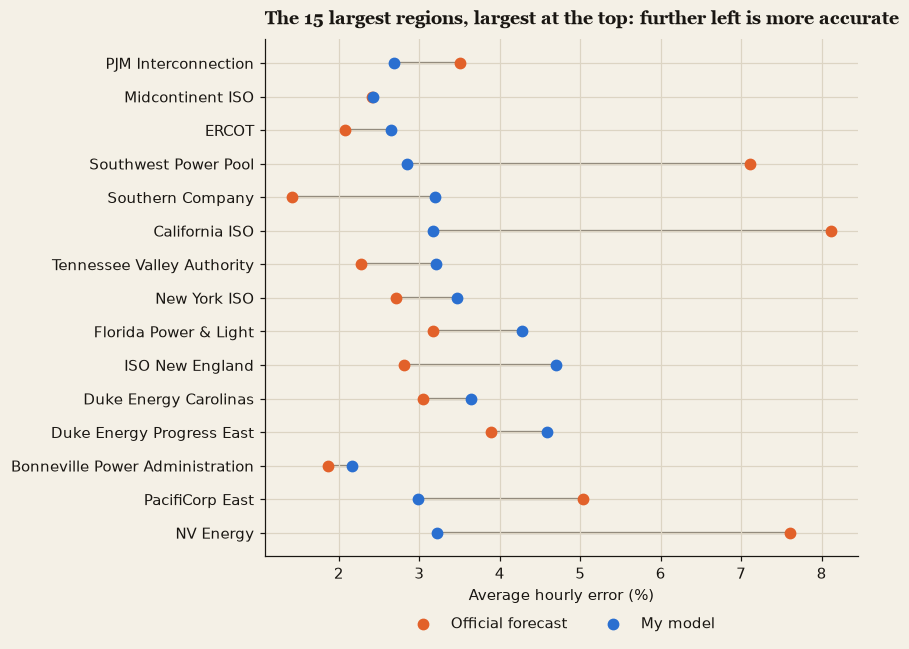

In [8]:
t = by_region.sort_values("avg_demand_gw", ascending=True).tail(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.hlines(t.name, t.mine * 100, t.official * 100, color=GRAY, lw=1.5, zorder=1)
ax.scatter(t.official * 100, t.name, color=ORANGE, s=45, label="Official forecast", zorder=2)
ax.scatter(t.mine * 100, t.name, color=BLUE, s=45, label="My model", zorder=3)
ax.set_xlabel("Average hourly error (%)")
ax.set_title("The 15 largest regions, largest at the top: further left is more accurate", fontdict=SERIF)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, frameon=False)
plt.tight_layout()

In [9]:
# Biggest leads each way, as a share of the official error
by_region["difference"] = by_region.mine / by_region.official - 1
show = ["name", "avg_demand_gw", "mine", "official", "difference"]
print("Where my model leads most:")
display(by_region.nsmallest(5, "difference")[show])
print("Where the operator leads most:")
display(by_region.nlargest(5, "difference")[show])

Where my model leads most:


,name,avg_demand_gw,mine,official,difference
4,California ISO,26.681,0.032,0.081,-0.610
8,Florida Municipal Power Pool,2.244,0.039,0.100,-0.608
27,Southwest Power Pool,34.605,0.028,0.071,-0.600
16,NV Energy,4.883,0.032,0.076,-0.576
22,Public Service Co. of New Mexico,1.706,0.030,0.062,-0.517


Where the operator leads most:


,name,avg_demand_gw,mine,official,difference
0,Associated Electric Coop.,2.518,0.050,0.022,1.263
25,Southern Company,28.007,0.032,0.014,1.253
20,Portland General Electric,2.670,0.026,0.014,0.794
11,ISO New England,13.245,0.047,0.028,0.673
29,Tucson Electric Power,1.714,0.041,0.027,0.529


The model's biggest leads are in regions such as California and the Southwest Power Pool, where the official
forecast is unusually weak. The operators' biggest leads include Southern Company and ISO New England, two large
grids whose own forecasts are very accurate, plus several small utilities.

## 4. When the model wins: hour of day and season

For this comparison I keep only regions whose official forecast is clearly a real one (median error under 5%),
so a few weak official forecasts can't flatter my model.

My error is lower in 15 of 24 hours and 17 of 29 months.


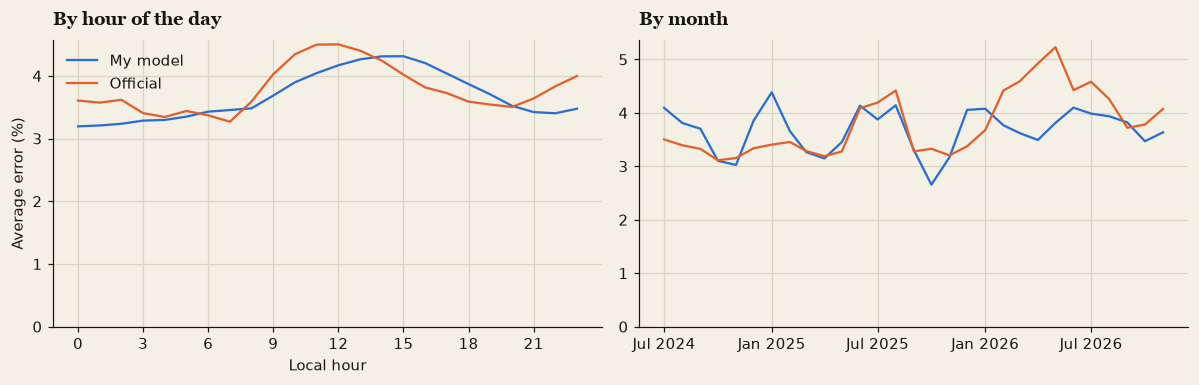

In [10]:
strict = h[h.in_strict_check]
by_hour = strict.groupby("local_hour")[["err_mine", "err_official"]].mean() * 100
by_month = strict.groupby(strict.local_date.dt.to_period("M"))[["err_mine", "err_official"]].mean() * 100

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
a.plot(by_hour.index, by_hour.err_mine, color=BLUE, label="My model")
a.plot(by_hour.index, by_hour.err_official, color=ORANGE, label="Official")
a.set(xlabel="Local hour", ylabel="Average error (%)", xticks=range(0, 24, 3), ylim=(0, None)); a.set_title("By hour of the day", fontdict=SERIF)
a.legend(frameon=False)
b.plot(by_month.index.to_timestamp(), by_month.err_mine, color=BLUE)
b.plot(by_month.index.to_timestamp(), by_month.err_official, color=ORANGE)
b.set(ylim=(0, None)); b.set_title("By month", fontdict=SERIF)
b.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
b.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
print(f"My error is lower in {(by_hour.err_mine < by_hour.err_official).sum()} of 24 hours "
      f"and {(by_month.err_mine < by_month.err_official).sum()} of {len(by_month)} months.")

My model is strongest overnight and weakest in the afternoon, when the operators' real-time information
(and their knowledge of their own system) matters most. By month there's no steady winner: the lead swings
with the season.

## 5. The days that matter most

The busiest days decide how many expensive standby power plants have to run, so errors there cost the most.
Here each region's days are split by how busy they were.

In [11]:
daily = strict.groupby(["region", "local_date"]).agg(
    demand=("actual_mw", "mean"), mine=("err_mine", "mean"), official=("err_official", "mean")).reset_index()
pct = daily.groupby("region").demand.rank(pct=True)
daily["kind"] = pd.cut(pct, [0, 0.05, 0.95, 1], labels=["Quietest 5% of days", "All other days", "Busiest 5% of days"])
(daily.groupby("kind", observed=True)[["mine", "official"]].mean() * 100).round(2)

,mine,official
kind,,
Quietest 5% of days,4.27,5.02
All other days,3.63,3.77
Busiest 5% of days,4.13,3.65


On the busiest days the operators are clearly better. That's the model's most important weakness, and the
reason a peak-focused model was tried (it didn't help; see the write-up). The daily-peak table confirms it:

In [12]:
p = peaks.merge(regions[["region", "in_headline", "avg_demand_mw"]], on="region")
p = p[p.in_headline]
for who in ("ours", "official"):
    p[who + "_peak_err"] = (p[who + "_peak_mw"] - p.actual_peak_mw).abs() / p.actual_peak_mw
    p[who + "_hour_hit"] = (p[who + "_peak_hour"] - p.actual_peak_hour).abs() <= 1
pr = p.groupby("region").agg(w=("avg_demand_mw", "first"), mine=("ours_peak_err", "mean"), official=("official_peak_err", "mean"),
                             mine_hit=("ours_hour_hit", "mean"), official_hit=("official_hour_hit", "mean"))
pw = pr.w / pr.w.sum()
pd.Series({"my peak error": (pr.mine * pw).sum(), "official peak error": (pr.official * pw).sum(),
           "peak hour within ±1 h (mine)": (pr.mine_hit * pw).sum(), "peak hour within ±1 h (official)": (pr.official_hit * pw).sum()})

my peak error                       0.033
official peak error                 0.029
peak hour within ±1 h (mine)        0.795
peak hour within ±1 h (official)    0.847
dtype: float64

## 6. Are the 80% prediction ranges honest?

Besides a single number, the model gives a range meant to contain the actual demand 80% of the time. If it's
honest, about 80% of hours should land inside it, overall and in each region.

Overall: 79.6% of hours inside the 80% range


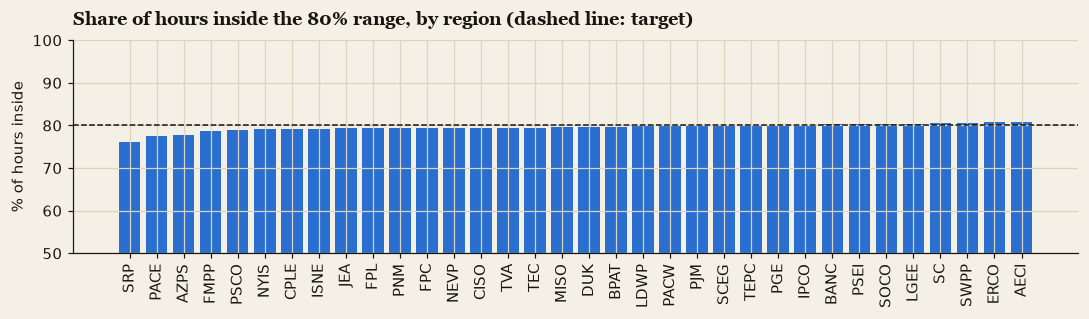

In [13]:
h["inside"] = (h.actual_mw >= h.ours_low_mw) & (h.actual_mw <= h.ours_high_mw)
cov = h.groupby("region").inside.mean().sort_values() * 100
print(f"Overall: {h.inside.mean():.1%} of hours inside the 80% range")
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(cov.index, cov.values, color=BLUE)
ax.axhline(80, color=INK, lw=1, ls="--")
ax.set(ylabel="% of hours inside", ylim=(50, 100)); ax.set_title("Share of hours inside the 80% range, by region (dashed line: target)", fontdict=SERIF)
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()

The ranges are honest: 79.6% of hours land inside them overall, and every region is between 76% and 81%.
The ranges were calibrated only on earlier quarters, so this is a genuine out-of-sample check.

## 7. Combining both forecasts

The two forecasts make different mistakes, so a weighted mix of them should beat either one. The weights were
learned only from earlier quarters, so the blend is as fair as the rest of the backtest.

In [14]:
pd.Series({
    "official error": (by_region.official * weights).sum(),
    "my error": (by_region.mine * weights).sum(),
    "blend error": (by_region.blend * weights).sum(),
    "blend vs official": (by_region.blend * weights).sum() / (by_region.official * weights).sum() - 1,
    "regions where the blend beats the official forecast": f"{(by_region.blend < by_region.official).sum()} of {len(by_region)}",
})

official error                                            0.037
my error                                                  0.031
blend error                                               0.025
blend vs official                                        -0.333
regions where the blend beats the official forecast    28 of 31
dtype: object

The blend cuts the operators' error by about a third and beats the official forecast in almost every region.
That's the most practical result: an operator doesn't have to replace its forecast to benefit from this model.

## 8. The biggest misses

In [15]:
worst = (fair.groupby(["region", "name", "local_date"])
         .agg(mine=("err_mine", "mean"), official=("err_official", "mean"), demand_gw=("actual_mw", lambda s: s.mean() / 1000))
         .reset_index())
worst = worst[worst.demand_gw > 5]          # regions averaging over 5 GW that day
worst.nlargest(8, "mine").assign(mine=lambda d: (d.mine * 100).round(1), official=lambda d: (d.official * 100).round(1),
                                  demand_gw=lambda d: d.demand_gw.round(1))

,region,name,local_date,mine,official,demand_gw
5257,DUK,Duke Energy Carolinas,2024-09-28,30.0,27.8,8.6
5256,DUK,Duke Energy Carolinas,2024-09-27,28.3,27.4,9.6
7841,FPL,Florida Power & Light,2024-10-10,28.0,8.7,14.0
23146,SRP,Salt River Project,2026-08-04,23.6,29.3,5.2
8320,FPL,Florida Power & Light,2026-02-01,22.7,3.9,22.1
7946,FPL,Florida Power & Light,2025-01-23,22.3,4.7,18.4
7945,FPL,Florida Power & Light,2025-01-22,21.8,5.2,17.8
9841,ISNE,ISO New England,2025-07-04,20.8,3.0,12.0


The worst days cluster around hurricanes (Helene in the Carolinas and Milton in Florida, autumn 2024), when
outages cut demand far below anything the weather forecast implied; around rare Florida cold snaps, when heating
demand spikes in a grid built around air conditioning; and around holidays such as July 4. On most of these days
the operator, who can see its own outages, did much better. A storm-warning signal was tested: it helped on
storm days but not overall, so it wasn't adopted (details in the write-up).

## 9. What it adds up to

- **Overall, weighted by demand, my model beats the operators** (about 3.1% vs 3.7% average error), mostly
  because it does well in the largest grids.
- **Region by region it's a split decision**: 12 significant wins, 14 losses and 5 ties. Small utilities often
  forecast their own systems better.
- **The operators win where it matters most**: on the busiest days and at the daily peak.
- **The prediction ranges are close to honest** (about 80% of hours inside an 80% range).
- **The best forecast uses both**: a blend cuts the operators' error by about a third.

The model now runs live: a new forecast is published every morning, before the day it predicts, on the
[website](https://maxliston.github.io/beat-the-grid/) and in [`forecasts/`](../forecasts/).